# Asset Pricing — Kernel

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from nlls_gram import RepeatedFactorMetric, RidgeLevenbergMarquardt

Structural parameters of the economic model. The dict `p` is the
solver’s differentiable-parameter pytree:
[`nlls-gram`](https://pypi.org/project/nlls-gram/) differentiates the
solve implicitly with respect to every leaf of `p`, so sensitivities of
the solution need no changes here.

In [2]:
r = 0.1  # interest rate
c = 0.02  # dividend flow constant
g = -0.2  # dividend growth rate
x_0 = 0.01  # initial dividend
p = {"r": r, "c": c, "g": g, "x_0": x_0}

Parameters of the algorithm: the kernel hyperparameters, the collocation
and test grids, and the ridge Levenberg–Marquardt settings.

In [3]:
ELL = 10.0  # Matern-1/2 length scale
SIGMA = 1.0  # kernel amplitude
TRAIN_T = 40.0
N_TRAIN = 41
TEST_T = 50.0
N_TEST = 100
RIDGE = 1e-10  # disappearing penalty weight
ATOL = 1e-9  # unscaled residual norm
GTOL = 1e-13
INIT_DAMPING = 1e-8
MAX_STEPS = 100

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)

## The model

An asset pays the deterministic dividend flow

$$x(t) = \left(x_0 + \frac{c}{g}\right) e^{g t} - \frac{c}{g},$$

and no-arbitrage at interest rate $r$ prices it by the linear ODE

$$p'(t) = r\, p(t) - x(t).$$

Every solution is the fundamental price plus a bubble,
$p(t) = p_f(t) + \zeta\, e^{r t}$, and the standard approach kills the
bubble with a terminal or boundedness condition. Here we impose **no
boundary condition at all**: the initial price $p_0$ is a free unknown,
and the minimum-norm selection of the kernel method (below) rules out
the explosive $e^{rt}$ mode on its own.

In [4]:
def dividends(t, p):
    return (p["x_0"] + p["c"] / p["g"]) * jnp.exp(p["g"] * t) - p["c"] / p["g"]

## The integrated kernel

The hypothesis class is an RKHS built from the Matérn-1/2 kernel

$$k(t, t') = \sigma^2 e^{-|t - t'|/\ell},
\qquad
h(d) = \int_0^d k(s, 0)\, ds = \sigma^2 \ell \left(1 - e^{-d/\ell}\right),$$

applied to the *derivative* of the price path. Integrating the
representer expansion once gives the integrated kernel

$$\tilde K(t_i, t_j) = \int_0^{t_i} k(s, t_j)\, ds
= h(t_j) + \operatorname{sign}(t_i - t_j)\, h(|t_i - t_j|),$$

so that a path and its derivative are, exactly,

$$p(t) = p_0 + \sum_j \alpha_j \tilde K(t, t_j),
\qquad
p'(t) = \sum_j \alpha_j k(t, t_j).$$

Since $\tilde K(0, \cdot) = 0$, the free constant $p_0$ is exactly the
initial price.

In [5]:
def antiderivative(d):
    return SIGMA**2 * ELL * (1.0 - jnp.exp(-d / ELL))


def kernel_matrices(t_i, t_j):
    s = t_i[:, None] - t_j[None, :]
    K = SIGMA**2 * jnp.exp(-jnp.abs(s) / ELL)
    K_tilde = antiderivative(t_j)[None, :] + jnp.sign(s) * antiderivative(jnp.abs(s))
    return K, K_tilde

## Ridgeless least squares

Stacking the no-arbitrage residual at every training date gives a
least-squares problem with a *disappearing penalty*,

$$\min_{\alpha, p_0}\ \| r(\alpha, p_0) \|^2 + \lambda\, \alpha^\top K \alpha,
\qquad
r_i = p'(t_i) - \big(r\, p(t_i) - x(t_i)\big).$$

As $\lambda \to 0$ the minimizer converges to the interpolant of minimal
RKHS norm $\alpha^\top K \alpha$ — the ridgeless limit — with the free
constant $p_0$ unpenalized. We pin $\lambda$ tiny and fixed (`RIDGE`),
accepting an $O(\lambda)$ bias. The explosive bubble mode has enormous
norm under this criterion, so the minimum-norm solution is the
fundamental price.

In [6]:
def residual_fn(theta, args, p):
    alpha, p_0 = theta["alpha"], theta["p_0"]
    price = p_0 + args["K_tilde"] @ alpha
    return args["K"] @ alpha - (p["r"] * price - dividends(args["t"], p))

## Solve

The penalty enters through a `RepeatedFactorMetric` holding the upper
Cholesky factor of the Gram matrix: it penalizes the leading coordinates
of the flattened `theta` — dicts flatten by sorted key, so `"alpha"`
leads — and leaves the trailing scalar $p_0$ as the unpenalized free
block. Because the residual is affine in `theta`, each ridge
Levenberg–Marquardt step is an exact kernel ridge solve; convergence
requires both the gradient (`gtol`) and residual (`atol`) tests.

In [7]:
K, K_tilde = kernel_matrices(t_train, t_train)
metric = RepeatedFactorMetric(jnp.linalg.cholesky(K, upper=True), repeats=1)
args = {"K": K, "K_tilde": K_tilde, "t": t_train}
# Flattened by sorted key: "alpha" (penalized by the metric) precedes the free "p_0".
theta_0 = {"alpha": jnp.zeros(N_TRAIN), "p_0": jnp.zeros(())}

solver = RidgeLevenbergMarquardt(
    residual_fn, metric=metric, ridge=RIDGE, init_damping=INIT_DAMPING
)
start = time.perf_counter()
result = solver.solve(
    theta_0,
    args,
    p=p,
    max_steps=MAX_STEPS,
    atol=ATOL,
    gtol=GTOL,
    max_steps_is_success=False,
)
solve_time = time.perf_counter() - start
alpha, p_0 = result.x["alpha"], result.x["p_0"]

## Results

Off-grid evaluation only needs fresh cross-kernel matrices against the
training dates. The model has a closed-form fundamental price to compare
against,

$$p_f(t) = \frac{x_0 + c/g}{r - g}\, e^{g t} - \frac{c}{g r},$$

so we report the no-arbitrage residual on the test grid (which extends
past the training horizon), the learned $p_0$ against $p_f(0) = 0.7$,
and the relative pricing error.

In [8]:
K_test, K_tilde_test = kernel_matrices(t_test, t_train)
price_test = p_0 + K_tilde_test @ alpha
test_residual = K_test @ alpha - (r * price_test - dividends(t_test, p))

# Closed-form fundamental (no-bubble) price.
price_fundamental = (x_0 + c / g) * jnp.exp(g * t_test) / (r - g) - c / (g * r)
rel_error = jnp.abs(price_test - price_fundamental) / price_fundamental

print(f"solve: {int(result.steps)} steps in {solve_time:.2f}s (incl. jit)")
print(f"p_0 = {float(p_0):.6f}")
print(f"max |test residual|: {float(jnp.max(jnp.abs(test_residual))):.3e}")
print(f"max rel error vs fundamental: {float(jnp.max(rel_error)):.3e}")

solve: 11 steps in 0.24s (incl. jit)
p_0 = 0.699482
max |test residual|: 2.035e-04
max rel error vs fundamental: 1.707e-03

The kernel price tracks the closed-form fundamental with no bubble,
degrading only as it extrapolates past the training horizon (dotted).

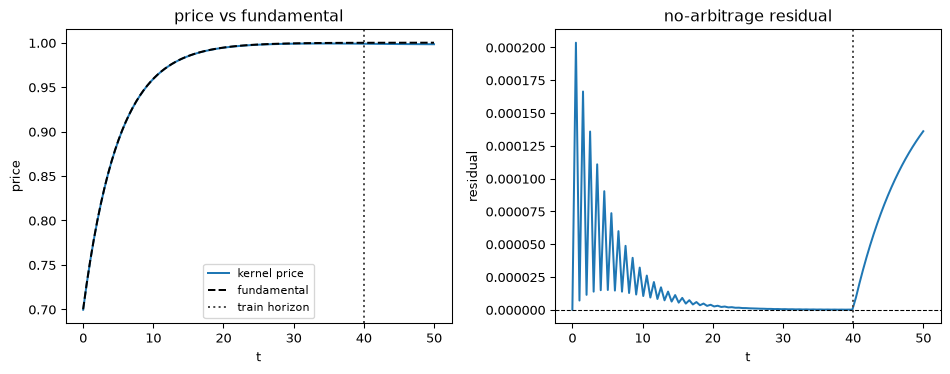

In [9]:
fig, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_p.plot(t_test, price_test, "C0", label="kernel price")
ax_p.plot(t_test, price_fundamental, "k--", label="fundamental")
ax_p.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_p.set(xlabel="t", ylabel="price", title="price vs fundamental")
ax_p.legend(fontsize=8)
ax_r.plot(t_test, test_residual, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="no-arbitrage residual")
fig.tight_layout()
plt.show()